# [02] Data Preparation & Preprocessing


## Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Find the project root
ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src").exists()
)

# Allow imports from src/
sys.path.insert(0, str(ROOT))

from src import config
from src.preprocessing import (
    BINARY_FEATURES,
    MODEL_FEATURES,
    NOMINAL_FEATURES,
    NUMERIC_FEATURES,
    ORDINAL_FEATURES,
    build_model_pipeline,
    build_preprocessor,
    prepare_features,
    prepare_target,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## Load the training set only

In [2]:
train_path = config.DATA_INTERIM / "train.csv"

if not train_path.exists():
    raise FileNotFoundError("train.csv was not found")

train = pd.read_csv(train_path)

print("training shape: ",train.shape)
train.head()

training shape:  (1600, 17)


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0727,21,Female,2,5.2,18.6,2.59,6.2,10.4,Moderate,7.3,7.7,76.1,No,Average,No,Medium
1,STU1385,23,Female,1,4.9,12.3,2.23,6.4,8.9,High,4.4,7.2,81.7,No,Average,No,Medium
2,STU1580,19,Female,2,7.2,17.0,2.21,5.7,7.2,Moderate,5.4,7.9,90.6,No,Average,No,Medium
3,STU1099,23,Female,1,8.3,19.5,2.87,6.9,10.4,Moderate,7.5,4.8,83.5,No,Average,No,Low
4,STU0583,22,Female,3,7.2,23.8,2.47,5.6,8.0,High,7.2,7.8,74.6,Yes,Average,Yes,Medium


## Check required columns

In [3]:
required_columns = [config.ID_COL,*MODEL_FEATURES,config.TARGET_COL]

missing_columns = [
    column
    for column in required_columns
    if column not in train.columns
]

extra_columns = [
    column
    for column in train.columns
    if column not in required_columns
]

print("Missing columns:", missing_columns)
print("Extra columns:", extra_columns)

assert len(missing_columns) == 0, (
    f"Required columns are missing: {missing_columns}"
)


Missing columns: []
Extra columns: []


## Separate features & target

In [7]:
X_train = prepare_features(train)
y_train = prepare_target(train)

print("X_train shape: ",X_train.shape)
print("y_train shape: ",y_train.shape)

print("\nStudent_ID included in X_train:")
print(config.ID_COL in X_train.columns)

print("\nTarget included in X_train:")
print(config.TARGET_COL in X_train.columns)

X_train shape:  (1600, 15)
y_train shape:  (1600,)

Student_ID included in X_train:
False

Target included in X_train:
False


## Missing values before preprocessing

In [8]:
missing_before = pd.DataFrame({
    "missing_count":X_train.isna().sum(),
    "missing_pct":(X_train.isna().mean()*100).round(2)
})

missing_before = missing_before[missing_before["missing_count"] > 0]

missing_before

,missing_count,missing_pct
Sleep_Hours,54,3.38
GPA,36,2.25
Social_Media_Hours,48,3.00
Financial_Stress,76,4.75
Family_Support,36,2.25
Attendance_Rate,39,2.44
Diet_Quality,55,3.44


## Plot missing values


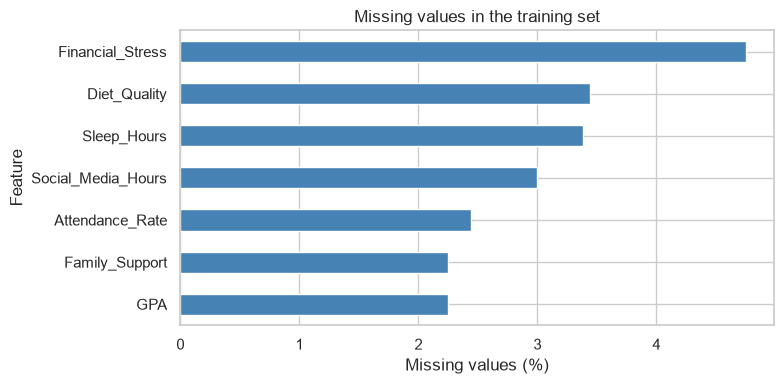

In [9]:
if len(missing_before) > 0:
    missing_before["missing_pct"].sort_values().plot(
        kind="barh",
        figsize=(8,4),
        color = "steelblue"
    )

    plt.title("Missing values in the training set")
    plt.xlabel("Missing values (%)")
    plt.ylabel("Feature")
    plt.tight_layout()

    output_path = config.FIGURES / "02_missing_values_train.png"
    plt.savefig(output_path,dpi = 120)
    plt.show()
else:
    print("No Missing values found")

## Target Distribution

In [11]:
target_distribution = pd.DataFrame({
    "count": y_train.value_counts().reindex(config.TARGET_ORDER),
    "percentage": (y_train.value_counts(normalize=True).reindex(config.TARGET_ORDER).mul(100).round(2)),
})

target_distribution

,count,percentage
Mental_Health_Risk,,
Low,528,33.0
Medium,528,33.0
High,544,34.0


## Check class Imblance

The target is approximately balanced _33%_ _33%_ _34%_

## Plot the training target

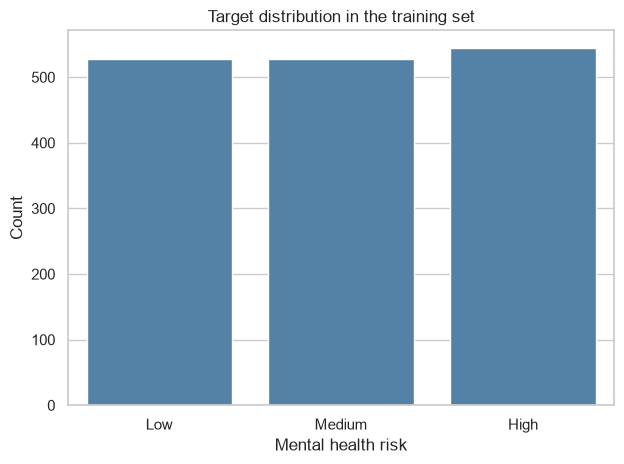

In [13]:
sns.countplot(
    x=y_train,
    order=config.TARGET_ORDER,
    color="steelblue",
)

plt.title("Target distribution in the training set")
plt.xlabel("Mental health risk")
plt.ylabel("Count")
plt.tight_layout()

output_path = config.FIGURES / "02_target_distribution_train.png"
plt.savefig(output_path,dpi=120)
plt.show()

## Build the Preprocessor

In [14]:
preprocessor = build_preprocessor()

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('nominal', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per tra

## Fit the preprocessor on training data

In [15]:
X_train_transformed = preprocessor.fit_transform(X_train)

print("Original shape: ",X_train.shape)
print("Transformed shape: ",X_train_transformed.shape)

Original shape:  (1600, 15)
Transformed shape:  (1600, 17)


## Get Transformed feature names

In [16]:
feature_names = preprocessor.get_feature_names_out()
print("Number of transformed features", len(feature_names))

feature_names

Number of transformed features 17


array(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week',
       'GPA', 'Social_Media_Hours', 'Screen_Time_Hours',
       'Financial_Stress', 'Family_Support', 'Attendance_Rate',
       'Gender_Female', 'Gender_Male', 'Gender_Non-binary',
       'Physical_Activity', 'Diet_Quality', 'Part_Time_Job',
       'Previous_Mental_Health_History'], dtype=object)

## Create a transformed DataFrame

In [17]:
X_train_ready = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index,
)
X_train_ready.head()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate,Gender_Female,Gender_Male,Gender_Non-binary,Physical_Activity,Diet_Quality,Part_Time_Job,Previous_Mental_Health_History
0,-0.063706,-0.471636,-1.404182,-0.238603,0.074214,0.148597,1.098992,0.713748,0.643008,-1.244652,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1,0.875744,-1.232340,-1.676036,-1.330997,-0.976093,0.327697,0.194658,-0.842691,0.368687,-0.465696,1.0,0.0,0.0,2.0,1.0,0.0,0.0
2,-1.003157,-0.471636,0.408177,-0.516037,-1.034443,-0.299153,-0.830254,-0.305988,0.752736,0.772288,1.0,0.0,0.0,1.0,1.0,0.0,0.0
3,0.875744,-1.232340,1.404975,-0.082547,0.891120,0.775447,1.098992,0.821088,-0.948052,-0.215317,1.0,0.0,0.0,1.0,1.0,0.0,0.0
4,0.406019,0.289067,0.408177,0.663055,-0.275888,-0.388703,-0.347943,0.660077,0.697872,-1.453301,1.0,0.0,0.0,2.0,1.0,1.0,1.0


## Check missing values after preprocessing

In [18]:
total_missing_after = X_train_ready.isna().sum().sum()

print("total_missing_after_preprocessing: ",total_missing_after)

assert total_missing_after == 0,("the transformed data still contains missing values")

total_missing_after_preprocessing:  0


## check transformed data types

In [19]:
print(X_train_ready.dtypes.value_counts())

assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train_ready.dtypes)

print("All transformed features are numeric")

float64    17
Name: count, dtype: int64
All transformed features are numeric


## Check numeric scaling

In [20]:
scaled_numeric_columns = X_train_ready[NUMERIC_FEATURES]

scaling_check = pd.DataFrame({
    "mean" : scaled_numeric_columns.mean().round(3),
    "standard_deviation":scaled_numeric_columns.std().round(3),
})

scaling_check

,mean,standard_deviation
Age,-0.0,1.0
Year_of_Study,-0.0,1.0
Sleep_Hours,0.0,1.0
Study_Hours_Per_Week,0.0,1.0
GPA,-0.0,1.0
Social_Media_Hours,-0.0,1.0
Screen_Time_Hours,-0.0,1.0
Financial_Stress,-0.0,1.0
Family_Support,0.0,1.0
Attendance_Rate,-0.0,1.0


## check ordinal encoding

In [26]:
ordinal_columns = [
    "Physical_Activity",
    "Diet_Quality",
]

for column in ordinal_columns:
    print(f"\n{column}:")
    # print((sorted(X_train_ready[column].unique())))
    print([float(value) for value in sorted(X_train_ready[column].unique())])


Physical_Activity:
[0.0, 1.0, 2.0]

Diet_Quality:
[0.0, 1.0, 2.0]


## check binary encoding

In [34]:
for column in BINARY_FEATURES:
    print(f"\n{column}: ")
    print([int(value) for value in sorted(X_train_ready[column].unique())])


Part_Time_Job: 
[0, 1]

Previous_Mental_Health_History: 
[0, 1]


## Create Complete Model Pipeline

In [36]:
from sklearn.linear_model import LogisticRegression

temporaray_model = LogisticRegression(
    max_iter=1000,
    random_state=config.RANDOM_STATE,
)

complete_pipeline = build_model_pipeline(temporaray_model)

complete_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('nominal', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""

## check pipeline steps

In [37]:
print("Pipeline steps: ")

for step_name,step_object in complete_pipeline.steps:
    print(f"- {step_name}: {type(step_object).__name__}")

Pipeline steps: 
- preprocessor: ColumnTransformer
- model: LogisticRegression


## Fit The tempopary pipeline

In [38]:
complete_pipeline.fit(X_train,y_train)

sample_predictions = complete_pipeline.predict(X_train.head(5))

print("sample predictions: ",sample_predictions)


sample predictions:  ['High' 'Medium' 'Low' 'Low' 'Medium']


## _Conclusion_

- `Student_ID` is excluded.
- Missing numeric values are imputed with the median.
- Missing categorical values are imputed with the most frequent category.
- Numeric variables are standardized.
- `Gender` is one-hot encoded.
- `Physical_Activity` and `Diet_Quality` are ordinally encoded.
- Binary variables are encoded as No = 0 and Yes = 1.
- The target is approximately balanced. SMOTE is not used by default.
